                                                          **EDA Using Visualization**

Setup, Data Loading & Missing Value Handling

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# 1. Load Titanic dataset
df = pd.read_csv("Titanic.csv")

# 2. Basic Exploration
print("--- DATA INFO ---")
df.info()

print("\n--- SUMMARY STATISTICS ---")
print(df.describe())

# 3. Handling Missing Values
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
# Feature Engineering for Q5b
df["FamilySize"] = df["SibSp"] + df["Parch"]

print("\nMissing values after cleaning:")
print(df.isnull().sum())

--- DATA INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

--- SUMMARY STATISTICS ---
       PassengerId    Survived      Pclass         Age       SibSp  \
count   891.000000  891.000000  891.000000  714.000000  891.000000   
mean    446.000000    0.383838    2.308642   29.699118    

Q1. Create a countplot to show the number of passengers by gender.

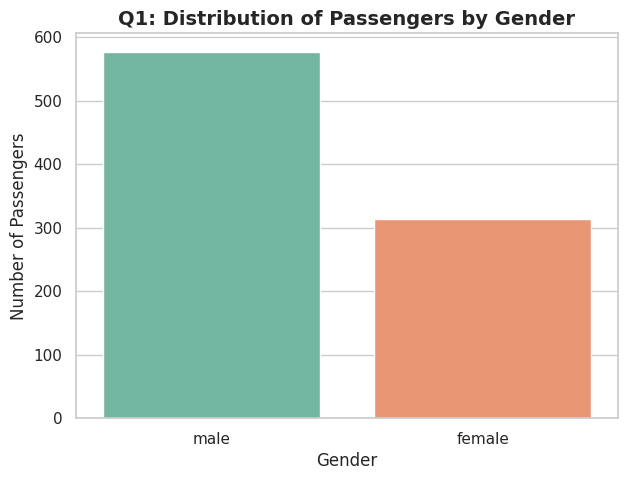

In [2]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Sex", hue="Sex", palette="Set2", legend=False)
plt.title("Q1: Distribution of Passengers by Gender", fontsize=14, weight="bold")
plt.xlabel("Gender", fontsize=12)
plt.ylabel("Number of Passengers", fontsize=12)
plt.show()

Interpretation: The dataset consists of significantly more male passengers (577) than female passengers (314). Males constituted roughly 65% of the total travelers on board.

Q2. Create a bar chart to show the number of passengers in each passenger class using different colors.

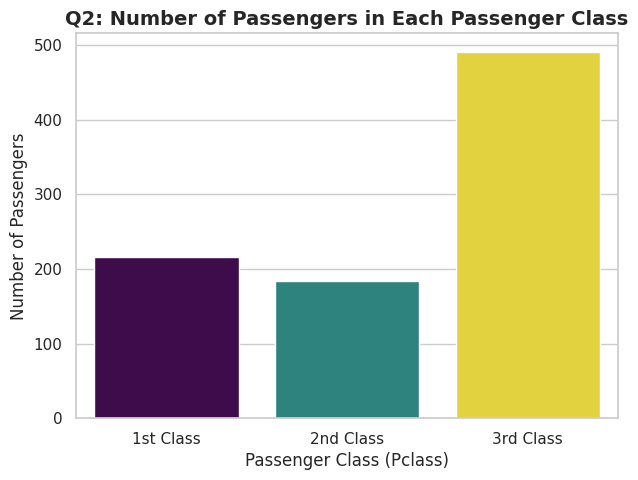

In [3]:
plt.figure(figsize=(7, 5))
sns.countplot(
    data=df, x="Pclass", hue="Pclass", palette="viridis", legend=False
)
plt.title(
    "Q2: Number of Passengers in Each Passenger Class",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Passenger Class (Pclass)", fontsize=12)
plt.ylabel("Number of Passengers", fontsize=12)
plt.xticks(ticks=[0, 1, 2], labels=["1st Class", "2nd Class", "3rd Class"])
plt.show()

Interpretation: Third-class passengers formed the largest group (491 passengers), surpassing first class (216) and second class (184) combined. This highlights that the vast majority of travelers were in lower-tier accommodations.

Q3. Create a histogram to show the distribution of passenger age.

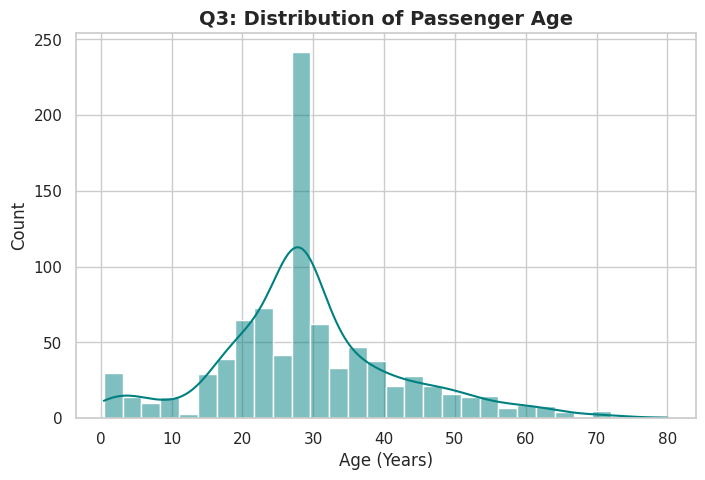

In [4]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], bins=30, kde=True, color="teal")
plt.title("Q3: Distribution of Passenger Age", fontsize=14, weight="bold")
plt.xlabel("Age (Years)", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.show()

Interpretation: The age distribution is right-skewed, with the majority of passengers concentrated between 20 and 40 years old. A noticeable peak around age 28 is visible due to median imputation, alongside a smaller spike among infants and young children.

Q4. Create a boxplot to detect outliers in the fare column.

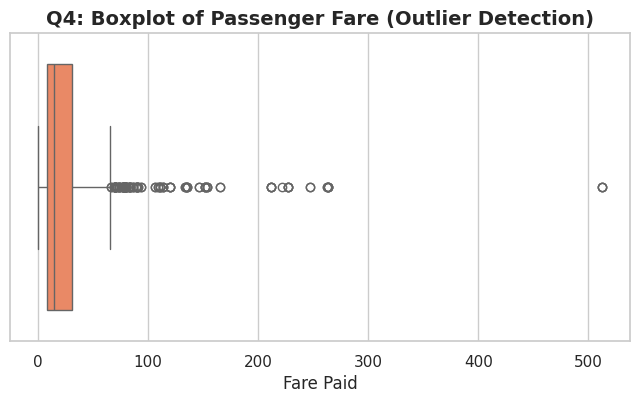

In [5]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Fare"], color="coral")
plt.title(
    "Q4: Boxplot of Passenger Fare (Outlier Detection)",
    fontsize=14,
    weight="bold",
)
plt.xlabel("Fare Paid", fontsize=12)
plt.show()

Interpretation: The boxplot demonstrates heavy positive skewness with extensive outliers extending past $100, reaching maximum fares of over $512. While the median fare is low (around $14), luxury first-class suites skew the distribution substantially.

Q5. Create a scatterplot to
     
     a. show the relationship between age and fare.
     
     b. analyze the relationship between family size (SibSp + Parch) and fare.

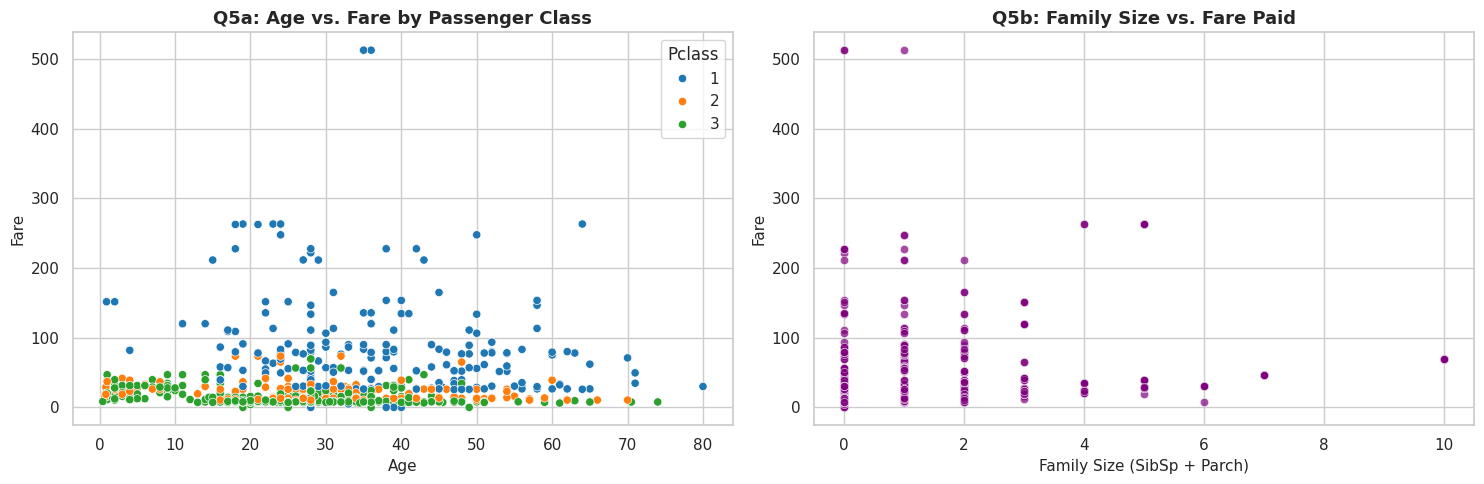

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Q5a: Age vs Fare
sns.scatterplot(
    ax=axes[0], data=df, x="Age", y="Fare", hue="Pclass", palette="tab10"
)
axes[0].set_title(
    "Q5a: Age vs. Fare by Passenger Class", fontsize=13, weight="bold"
)
axes[0].set_xlabel("Age", fontsize=11)
axes[0].set_ylabel("Fare", fontsize=11)

# Q5b: Family Size vs Fare
sns.scatterplot(
    ax=axes[1], data=df, x="FamilySize", y="Fare", color="purple", alpha=0.7
)
axes[1].set_title("Q5b: Family Size vs. Fare Paid", fontsize=13, weight="bold")
axes[1].set_xlabel("Family Size (SibSp + Parch)", fontsize=11)
axes[1].set_ylabel("Fare", fontsize=11)

plt.tight_layout()
plt.show()

Interpretation:

a. (Age vs. Fare): High fares were largely paid by middle-aged and older adults traveling in First Class. Most travelers across all age brackets paid fares under $100.

b. (Family Size vs. Fare): Solo travelers and small families (1–3 members) account for the highest ticket prices (likely purchasing premium suites). Very large families (5+ members) paid moderate total fares, primarily occupying lower classes.

Q6. Create a countplot to show survival count by gender.

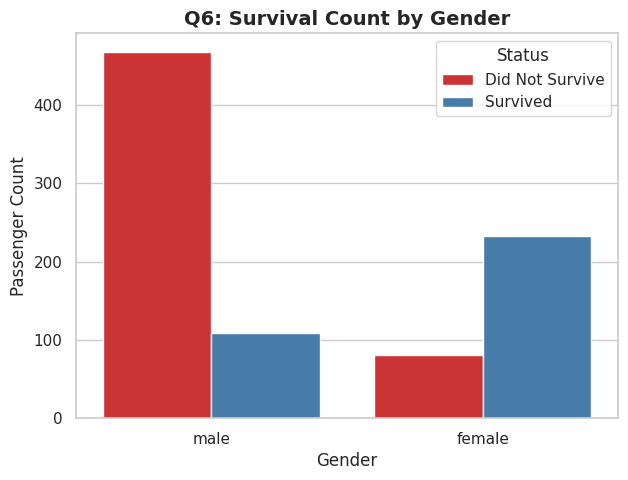

In [7]:
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Sex", hue="Survived", palette="Set1")
plt.title("Q6: Survival Count by Gender", fontsize=14, weight="bold")
plt.xlabel("Gender", fontsize=12)
plt.ylabel("Passenger Count", fontsize=12)
plt.legend(title="Status", labels=["Did Not Survive", "Survived"])
plt.show()

Interpretation: Gender was one of the strongest predictors of survival. Approximately 74.2% of female passengers survived, whereas only 18.9% of male passengers survived, directly reflecting the "women and children first" maritime evacuation protocol.

Q7. Create a bar chart to show survival by passenger class.

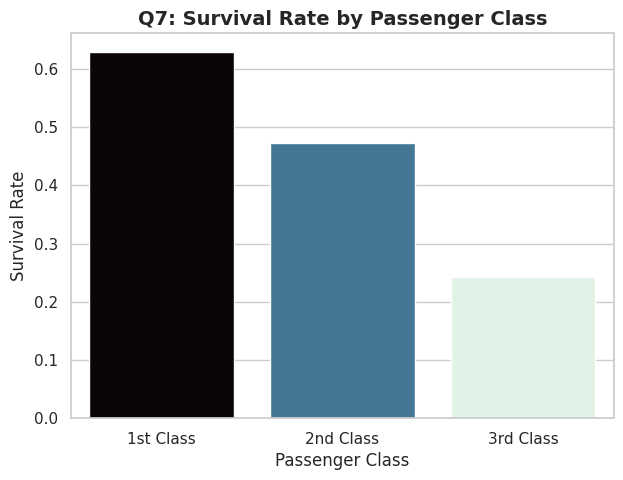

In [8]:
plt.figure(figsize=(7, 5))
sns.barplot(
    data=df,
    x="Pclass",
    y="Survived",
    hue="Pclass",
    palette="mako",
    errorbar=None,
    legend=False,
)
plt.title("Q7: Survival Rate by Passenger Class", fontsize=14, weight="bold")
plt.xlabel("Passenger Class", fontsize=12)
plt.ylabel("Survival Rate", fontsize=12)
plt.xticks(ticks=[0, 1, 2], labels=["1st Class", "2nd Class", "3rd Class"])
plt.show()

Interpretation: Socioeconomic status had a direct impact on survival probability. First-class passengers achieved a survival rate of ~63%, second-class ~47.3%, and third-class only ~24.2%, due to closer deck proximity to lifeboats and prioritized evacuation.

Q8. Create a heatmap to show correlation between numerical variables.

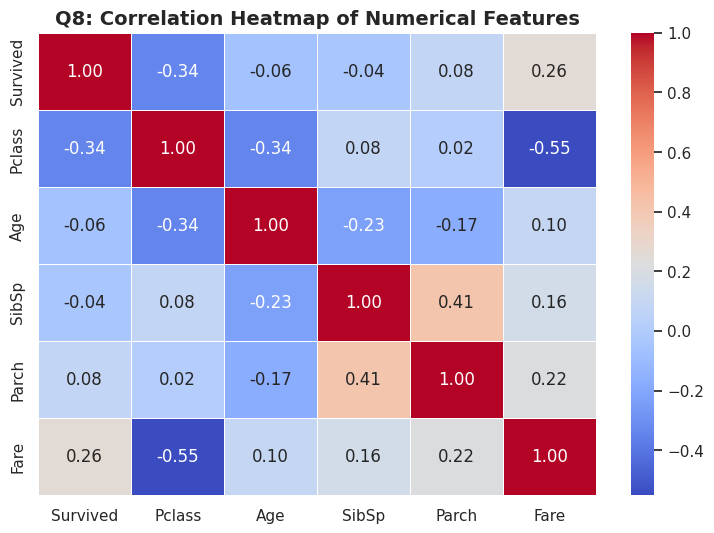

In [9]:
plt.figure(figsize=(9, 6))
numeric_df = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]]
corr_matrix = numeric_df.corr()

sns.heatmap(
    corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5
)
plt.title(
    "Q8: Correlation Heatmap of Numerical Features",
    fontsize=14,
    weight="bold",
)
plt.show()

**Interpretation:**
* `Fare` shows a positive correlation with `Survived` (+0.26), indicating passengers paying higher fares had higher survival chances.
* `Pclass` shows a negative correlation with `Survived` (-0.34), confirming that lower numerical classes (1st class) had higher survival rates.
* `SibSp` and `Parch` correlate positively (+0.41) as family members typically traveled together.

Q9. Identify which passenger class paid the highest fare on average.

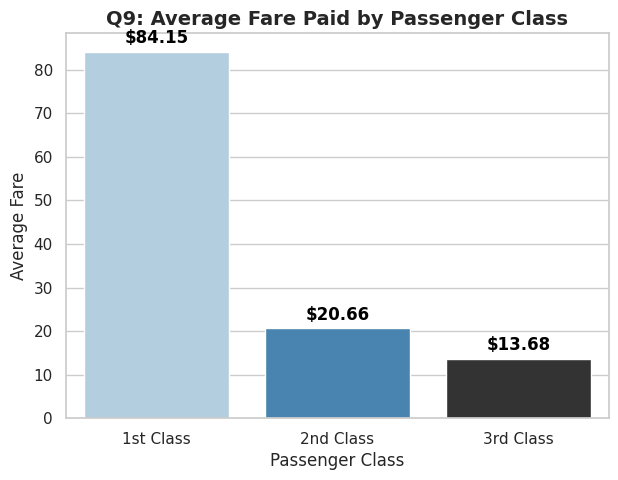

Average Fares by Class:
   Pclass       Fare
0       1  84.154687
1       2  20.662183
2       3  13.675550


In [10]:
avg_fare_by_class = df.groupby("Pclass")["Fare"].mean().reset_index()

plt.figure(figsize=(7, 5))
sns.barplot(
    data=avg_fare_by_class,
    x="Pclass",
    y="Fare",
    hue="Pclass",
    palette="Blues_d",
    legend=False,
)
plt.title(
    "Q9: Average Fare Paid by Passenger Class", fontsize=14, weight="bold"
)
plt.xlabel("Passenger Class", fontsize=12)
plt.ylabel("Average Fare", fontsize=12)
plt.xticks(ticks=[0, 1, 2], labels=["1st Class", "2nd Class", "3rd Class"])

for index, row in avg_fare_by_class.iterrows():
  plt.text(
      index,
      row.Fare + 2,
      f"${row.Fare:.2f}",
      color="black",
      ha="center",
      weight="bold",
  )

plt.show()

print("Average Fares by Class:")
print(avg_fare_by_class)

**Answer:** **1st Class** paid the highest fare on average, at **$84.15**, compared to **$20.66** for 2nd Class and **$13.68** for 3rd Class.

Q10. Write at least 5 insights from the dataset based on your visualizations.

### Final Insights from the Dataset:

1. **Gender Was the Single Strongest Survival Determinant:** Female passengers had an extraordinary survival rate (approximately 74.2%) compared to males (approximately 18.9%), reflecting adherence to the lifeboat evacuation protocol.
2. **Socioeconomic Status Heavily Influenced Survival:** Passengers in 1st class survived at more than 2.5 times the rate of 3rd-class passengers (63.0% vs. 24.2%), largely because higher-tier cabins were closer to the boat deck.
3. **Severe Fare Disparity:** The average fare for 1st class (USD 84.15) was over six times higher than 3rd class (USD 13.68), with notable luxury outliers exceeding USD 500.
4. **Demographic Concentration in Working-Age Adults:** The passenger base was predominantly male (around 65%) and young to middle-aged adults (20–40 years old), with 3rd class representing the largest single group on board.
5. **Family Size Dynamics:** Solo passengers and very large families suffered lower survival rates than small family units (2–4 members), who were best positioned to stay together and secure lifeboat seating.